## 1. Load the data and first look
**Goal:** check size, column types, class balance and missing values before any model.
**Finding:** ___ rows, ___ numeric and ___ text columns; ___% of loans are "bad".
**Decision:** ___


In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

data = fetch_openml("credit-g", version=1, as_frame=True)
X = data.data
y = data.target

print(X.shape)
print(y.value_counts())
print(y.value_counts(normalize=True).round(2))
print("Missing values:", X.isna().sum().sum())
X.info()
X.head()

(1000, 20)
class
good    700
bad     300
Name: count, dtype: int64
class
good    0.7
bad     0.3
Name: proportion, dtype: float64
Missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [2]:
X.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_status,1000,4,no checking,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,existing paid,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,10,radio/tv,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_status,1000,5,<100,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment,1000,5,1<=X<4,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment_commitment,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
personal_status,1000,4,male single,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_parties,1000,3,none,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
X.dtypes

checking_status           category
duration                     int64
credit_history            category
purpose                   category
credit_amount                int64
savings_status            category
employment                category
installment_commitment       int64
personal_status           category
other_parties             category
residence_since              int64
property_magnitude        category
age                          int64
other_payment_plans       category
housing                   category
existing_credits             int64
job                       category
num_dependents               int64
own_telephone             category
foreign_worker            category
dtype: object

## 2. Split and preprocessing recipe
**Goal:** lock the test set away and turn the text columns into numbers inside a recipe.
**Finding:** ___ train rows, ___ test rows; the recipe outputs ___ columns.
**Decision:** 1 = "bad" loan; no scaler, because boosting uses trees.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

y = (data.target == "bad").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(2), y_test.mean().round(2))

numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(include="category").columns.tolist()
assert set(numeric_cols + categorical_cols) == set(X_train.columns)

preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

out = preprocessor.fit_transform(X_train)
print(out.shape)

(800, 20) (200, 20)
0.3 0.3
(800, 61)


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5 , shuffle=True, random_state=42)

lazy = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent")),
])

scores = cross_validate(lazy, X_train, y_train, cv=cv, scoring=["precision", "recall", "f1","accuracy","roc_auc"])

print("accuracy:", scores["test_accuracy"].mean().round(2))
print("recall  :", scores["test_recall"].mean().round(2))
print("roc_auc :", scores["test_roc_auc"].mean().round(2))
print("f1      :", scores["test_f1"].mean().round(2))
print("precision:", scores["test_precision"].mean().round(2))

c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

accuracy: 0.7
recall  : 0.0
roc_auc : 0.5
f1      : 0.0
precision: 0.0


c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [6]:
from sklearn.tree import DecisionTreeClassifier

stump = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=1, random_state=42)),
])

scores = cross_validate(stump, X_train, y_train, cv=cv,
                        scoring=["accuracy", "recall", "precision", "roc_auc"])

for name in ["accuracy", "recall", "precision", "roc_auc"]:
    print(name, ":", scores[f"test_{name}"].mean().round(2))

c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

accuracy : 0.7
recall : 0.0
precision : 0.0
roc_auc : 0.67


c:\Users\rohit\ML_all\practice_task\Credit_Boosting\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [7]:
from sklearn.tree import export_text

stump.fit(X_train, y_train)
names = stump.named_steps["prep"].get_feature_names_out()
print(export_text(stump.named_steps["model"], feature_names=list(names)))

|--- cat__checking_status_no checking <= 0.50
|   |--- class: 0
|--- cat__checking_status_no checking >  0.50
|   |--- class: 0



In [8]:
print(y_train.groupby(X_train["checking_status"]).agg(["mean", "count"]).round(2))

                 mean  count
checking_status             
0<=X<200         0.39    214
<0               0.48    219
>=200            0.25     51
no checking      0.12    316


## 4. AdaBoost: re-weight the mistakes
**Goal:** combine many stumps, where each one focuses on the loans the earlier ones got wrong.
**Finding:** ___
**Decision:** ___

In [9]:
from sklearn.ensemble import AdaBoostClassifier

ada = Pipeline([
    ("prep", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=50,
        random_state=42)),
])

scores = cross_validate(ada, X_train, y_train, cv=cv,
                        scoring=["accuracy", "recall", "precision", "roc_auc"])

for name in ["accuracy", "recall", "precision", "roc_auc"]:
    print(name, ":", scores[f"test_{name}"].mean().round(2))

accuracy : 0.73
recall : 0.41
precision : 0.57
roc_auc : 0.77


In [10]:
rows = []
for n in [10, 50, 200, 500]:
    model = Pipeline([
        ("prep", preprocessor),
        ("model", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),
            n_estimators=n, random_state=42)),
    ])
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "recall"])
    rows.append({"n_estimators": n,
                 "auc_mean": s["test_roc_auc"].mean(),
                 "auc_std": s["test_roc_auc"].std(),
                 "recall": s["test_recall"].mean()})

print(pd.DataFrame(rows).round(3))

   n_estimators  auc_mean  auc_std  recall
0            10     0.736    0.045   0.229
1            50     0.775    0.046   0.408
2           200     0.784    0.043   0.462
3           500     0.780    0.040   0.488


In [11]:
# import numpy as np
# import matplotlib.pyplot as plt

# X_enc = preprocessor.fit_transform(X_train)   # train only, inspection only
# y_arr = y_train.to_numpy()

# n = len(y_arr)
# w = np.full(n, 1 / n)
# history = [w.copy()]
# times_wrong = np.zeros(n)
# rows = []

# for r in range(1, 6):
#     stump = DecisionTreeClassifier(max_depth=1, random_state=42)
#     stump.fit(X_enc, y_arr, sample_weight=w)          # LINE 1
#     wrong = stump.predict(X_enc) != y_arr
#     err = w[wrong].sum()                              # weighted error
#     alpha = np.log((1 - err) / err)                   # stump's vote strength
#     w = w * np.exp(alpha * wrong)                     # LINE 2
#     w = w / w.sum()
#     times_wrong += wrong
#     history.append(w.copy())
#     rows.append({"round": r, "stump_error": round(err, 3),
#                  "weight_on_wrong_after": round(w[wrong].sum(), 3)})

# print(pd.DataFrame(rows))

# H = np.array(history)
# hard = np.argsort(-times_wrong)[:4]                   # 4 loans missed most often
# for i in hard:
#     plt.plot(range(6), H[:, i], marker="o", label=f"loan {i}")
# plt.axhline(1 / n, color="gray", linestyle="--", label="start weight")
# plt.xlabel("round"); plt.ylabel("loan weight"); plt.legend(); plt.show()

In [13]:
import numpy as np

rows = []
for lr in [0.05, 0.1, 0.5, 1.0]:
    model = Pipeline([
        ("prep", preprocessor),
        ("model", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),
            n_estimators=200, learning_rate=lr, random_state=42)),
    ])
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "recall"])
    rows.append({"learning_rate": lr,
                 "auc_mean": s["test_roc_auc"].mean(),
                 "auc_std": s["test_roc_auc"].std(),
                 "recall": s["test_recall"].mean()})

table = pd.DataFrame(rows)
table["noise"] = table["auc_std"] / np.sqrt(5)
table["gap_from_best"] = table["auc_mean"].max() - table["auc_mean"]
table["tied_with_best"] = table["gap_from_best"] < table["noise"]
print(table.round(3))

   learning_rate  auc_mean  auc_std  recall  noise  gap_from_best  \
0           0.05     0.737    0.041   0.033  0.018          0.047   
1           0.10     0.745    0.040   0.112  0.018          0.039   
2           0.50     0.783    0.045   0.346  0.020          0.001   
3           1.00     0.784    0.043   0.462  0.019          0.000   

   tied_with_best  
0           False  
1           False  
2            True  
3            True  


## 4. AdaBoost: re-weight the mistakes
**Goal:** combine many stumps, where each one focuses on the loans the earlier ones got wrong.
**Finding:** One stump: AUC 0.67, recall 0. AdaBoost with 50 stumps: AUC 0.775, recall 0.41. 10 stumps are clearly worse (AUC 0.736); 50, 200 and 500 are tied within the noise (about 0.02). A small learning_rate needs more stumps (rate x stumps is roughly the total learning).
**Decision:** AdaBoost with n_estimators=50, learning_rate=1.0, the simplest of the tied models.

## 5. Gradient Boosting: fix the remaining errors
**Goal:** build trees one by one, where each new tree learns what is still wrong.
**Finding:** ___
**Decision:** ___

In [14]:
from sklearn.ensemble import GradientBoostingClassifier

gb = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)),
])

scores = cross_validate(gb, X_train, y_train, cv=cv,
                        scoring=["accuracy", "recall", "precision", "roc_auc"])

for name in ["accuracy", "recall", "precision", "roc_auc"]:
    print(name, ":", scores[f"test_{name}"].mean().round(2),
          "+/-", scores[f"test_{name}"].std().round(3))

accuracy : 0.73 +/- 0.018
recall : 0.4 +/- 0.063
precision : 0.56 +/- 0.044
roc_auc : 0.78 +/- 0.036


best validation AUC: 0.782 at 130 trees
at 300 trees  train: 1.0  validation: 0.776


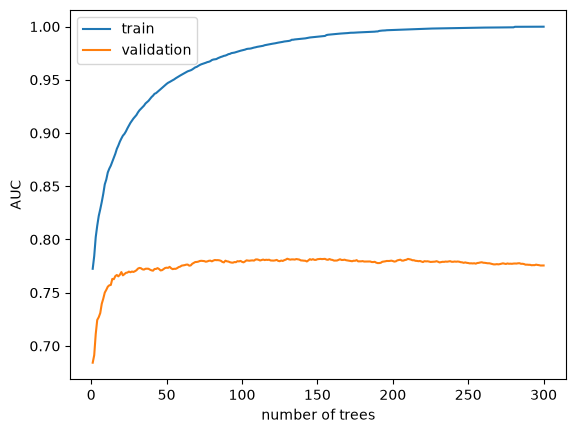

In [15]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

n_trees = 300
train_curves, val_curves = [], []

for tr, va in cv.split(X_train, y_train):
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", GradientBoostingClassifier(
            n_estimators=n_trees, learning_rate=0.1,
            max_depth=3, random_state=42)),
    ])
    pipe.fit(X_train.iloc[tr], y_train.iloc[tr])

    prep, mdl = pipe.named_steps["prep"], pipe.named_steps["model"]
    Z_tr = prep.transform(X_train.iloc[tr])
    Z_va = prep.transform(X_train.iloc[va])

    train_curves.append([roc_auc_score(y_train.iloc[tr], p[:, 1])
                         for p in mdl.staged_predict_proba(Z_tr)])
    val_curves.append([roc_auc_score(y_train.iloc[va], p[:, 1])
                       for p in mdl.staged_predict_proba(Z_va)])

train_mean = np.mean(train_curves, axis=0)
val_mean = np.mean(val_curves, axis=0)

print("best validation AUC:", val_mean.max().round(3),
      "at", val_mean.argmax() + 1, "trees")
print("at 300 trees  train:", train_mean[-1].round(3),
      " validation:", val_mean[-1].round(3))

plt.plot(range(1, n_trees + 1), train_mean, label="train")
plt.plot(range(1, n_trees + 1), val_mean, label="validation")
plt.xlabel("number of trees"); plt.ylabel("AUC"); plt.legend(); plt.show()

learning_rate=0.03: best AUC 0.783 at 292 trees
learning_rate=0.1: best AUC 0.782 at 130 trees
learning_rate=0.3: best AUC 0.777 at 149 trees


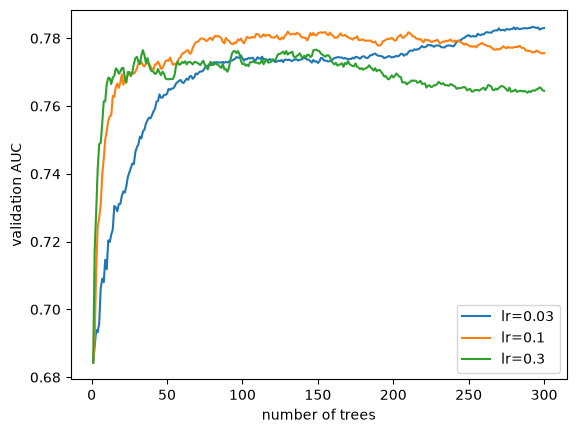

In [16]:
def val_curve(lr, n_trees=300):
    curves = []
    for tr, va in cv.split(X_train, y_train):
        pipe = Pipeline([
            ("prep", preprocessor),
            ("model", GradientBoostingClassifier(
                n_estimators=n_trees, learning_rate=lr,
                max_depth=3, random_state=42)),
        ])
        pipe.fit(X_train.iloc[tr], y_train.iloc[tr])
        Z_va = pipe.named_steps["prep"].transform(X_train.iloc[va])
        curves.append([roc_auc_score(y_train.iloc[va], p[:, 1])
                       for p in pipe.named_steps["model"].staged_predict_proba(Z_va)])
    return np.mean(curves, axis=0)

for lr in [0.03, 0.1, 0.3]:
    c = val_curve(lr)
    plt.plot(range(1, 301), c, label=f"lr={lr}")
    print(f"learning_rate={lr}: best AUC {c.max():.3f} at {c.argmax() + 1} trees")

plt.xlabel("number of trees"); plt.ylabel("validation AUC"); plt.legend(); plt.show()

## 5. Gradient Boosting: fix the remaining errors
**Goal:** build trees one by one, where each new tree learns what is still wrong.
**Finding:** Gradient Boosting (100 trees, depth 3) has AUC 0.78 +/- 0.036, tied with AdaBoost (0.775). Train AUC reaches 1.0 while validation stays near 0.78: the extra trees only memorize. Validation is flat from about 70 trees. A bigger learning_rate peaks sooner and then falls; learning_rate 0.03 is still rising at 300 trees. All three peaks are within the noise (about 0.016).
**Decision:** learning_rate=0.1, n_estimators=100, max_depth=3, the simplest steady setting.

## 6. XGBoost: the same idea, faster, with extra brakes
**Goal:** see what XGBoost adds to Gradient Boosting: speed and ways to stop overfitting.
**Finding:** ___
**Decision:** ___

In [18]:
from xgboost import XGBClassifier

models = {
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
}

for name, m in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "recall"])
    print(f"{name:17s} AUC {s['test_roc_auc'].mean():.3f} +/- {s['test_roc_auc'].std():.3f}"
          f" | recall {s['test_recall'].mean():.2f}"
          f" | fit time {s['fit_time'].mean():.2f}s")

GradientBoosting  AUC 0.779 +/- 0.036 | recall 0.40 | fit time 0.15s
XGBoost           AUC 0.789 +/- 0.043 | recall 0.46 | fit time 0.10s
